Wiht this notebook we want to understand the influence of the choice of the parameter k on th results of the thesis. Thereby for the different datasets we tried different k for velotest and the upper bound calculation.  

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import torch
import velotest
import yaml
from matplotlib.colors import LogNorm
from scipy import stats
from tqdm import tqdm
from velotest.hypothesis_testing import run_hypothesis_test_on
from velotest.neighbors import find_neighbors


In [2]:
def calculateBound(adata, k=None, neighbors=True, number_neighbors=200): 
    if neighbors is True:
        nn_indices_optimal = find_neighbors(torch.tensor(adata.layers['Ms']), k_neighbors=number_neighbors)

    mins = torch.tensor([-2.]*len(adata))
    maxs = torch.tensor([-2.]*len(adata))
    for i in tqdm(range(len(adata))):
        cos = torch.nn.CosineSimilarity(dim=1, eps=1e-6)
        if neighbors is True:
            expression_all = torch.tensor(adata.layers['Ms'][nn_indices_optimal[i]][:,adata.var.velocity_genes])
        else:
            expression_all = torch.tensor(adata.layers['Ms'][:,adata.var.velocity_genes])
        expression_cell = torch.tensor(adata.layers['Ms'][i,adata.var.velocity_genes]).unsqueeze(0)
        velocity = torch.tensor(adata.layers['velocity'][i,adata.var.velocity_genes]).unsqueeze(0)
        cosines = cos(expression_all - expression_cell, velocity)
        cosines = torch.cat([cosines[:i], cosines[i+1:]])
        if k is None:
            mins[i] = torch.min(cosines)
            maxs[i] = torch.max(cosines)
        else:
            mins[i] = torch.mean(torch.topk(cosines, largest=False, k=k).values)
            maxs[i] = torch.mean(torch.topk(cosines, largest=True, k=k).values)

    return maxs

def bestVelocityEmbedded(adata, basis, num=200):
    # Run test - tsne
    uncorrected_p_values, h0_rejected, debug_dict = run_hypothesis_test_on(adata, 
                                                                           basis=basis, 
                                                                           number_neighbors_to_sample_from=num, 
                                                                           null_distribution="velocities-explicit", 
                                                                           cosine_empty_neighborhood=None, 
                                                                           correction="bonferroni", 
                                                                           restrict_to_velocity_genes=True, 
                                                                           exclusion_degree=10)
    statistics = debug_dict['statistics']

    # Calculate emmbeding test optimal statistic
    best_value = [statistics.get_max_value(offset=True)[1] for statistics in statistics if statistics is not None]

    return best_value

In [4]:
datasets = {
        "Pancreas_dynamical": "/mnt/volume/Johanna_Velotest/configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "/mnt/volume/Johanna_Velotest/configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "/mnt/volume/Johanna_Velotest/configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "/mnt/volume/Johanna_Velotest/configs/gastrulation.yaml",
        "Bone_marrow": "/mnt/volume/Johanna_Velotest/configs/bonemarrow.yaml",
        "PBMC": "/mnt/volume/Johanna_Velotest/configs/pbmc.yaml",
        "Covid": "/mnt/volume/Johanna_Velotest/configs/covid.yaml",
        "Retinal_development": "/mnt/volume/Johanna_Velotest/configs/retinal_development.yaml",
        "Human_HSC": "/mnt/volume/Johanna_Velotest/configs/humanHSC.yaml",
        "RPE_1": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/human_cerebral.yaml",
        "Hematopoiesis_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"/mnt/volume/Johanna_Velotest/configs/noEmbedding/GSE128365.yaml",
        "Zebra_NMP": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/zebra_NMP.yaml"
    }

cell = {}
gene = {}
for name, path in datasets.items():
    with open(path, "r") as f:
            config = yaml.safe_load(f)
   
    adata = sc.read(config["path"]) 
    cell[name] = adata.n_obs
    gene[name] = np.sum(adata.var.velocity_genes)

count_df = pd.DataFrame(list(cell.items()), columns=['Dataset', 'CellCount'])
gene_df = pd.DataFrame(list(gene.items()), columns=['Dataset', 'VelocityGenes'])

Try out how the computation work before settign it in a script

In [4]:
# This whoel part was just to understand how to run everything and than this was written in a script to run in the background. 
results = {}

for name, path in datasets.items():
    # Open and collect data information
    with open(path, "r") as f:
        config = yaml.safe_load(f)
    adata = sc.read(config["path"])
    
    neighbors = [10, 25, 50, 100, 200, 300, 400, 800, 1200, 1600, 2000] # Run this multiple times with different neighbors to see how it changes (merge and concatenate the files after)
    distances = {}
    # Upper bound with differnt neighbors
    for i, num in enumerate(neighbors):
        if (num+1000) >= adata.n_obs:
            print("Jump", name)
            continue
        print("noJump", name)
        upper_bound = calculateBound(adata, neighbors=True, number_neighbors=num)
    
        # Test optimal with original embedding
        bound = bestVelocityEmbedded(adata, config['basis'], num)

        distances[f"n_{num}"] = stats.wasserstein_distance(upper_bound, bound)

    results[name] = distances

df = pd.DataFrame(results)
df.to_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_zebra.csv")


noJump Zebra_NMP


100%|██████████| 16035/16035 [00:13<00:00, 1226.04it/s]


Dropping all the genes which are not velocity genes. 897 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 16035/16035 [00:07<00:00, 2175.70it/s]


Exclusion radius in rad: 0.17453292519943295
noJump Zebra_NMP


...

Exclusion radius in rad: 0.17453292519943295
noJump Zebra_NMP


100%|██████████| 16035/16035 [12:11<00:00, 21.93it/s]


Dropping all the genes which are not velocity genes. 897 genes left.
Number of workers:  9
Runnining with new modification


100%|██████████| 16035/16035 [42:23<00:00,  6.30it/s] 


Exclusion radius in rad: 0.17453292519943295


In [ ]:
# Load measuremnts for datasets and concatene them
#df1 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_subsample_recomputed_2000cells_zebra.csv", index_col=0)
#df_complete = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_subsample_recomputed_2000cells.csv", index_col=0)
#df2o = pd.concat([df_complete, df1], axis=1)
#df2o
## Save the one full table
#df2o.to_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_sub_2000cells.csv")


In [5]:
# Prepare some data and also some overall plotting schemes
df_complete = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_complete.csv", index_col=0)
df_long_complete = df_complete.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')

plot_df = pd.merge(df_long_complete, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']
print(plot_df)

# Prepare color scale 
vmin = plot_df['CellCount'].min()
vmax = plot_df['CellCount'].max()
log_norm = LogNorm(vmin=vmin, vmax=vmax)

      index             Dataset  Measurement  CellCount  Neighbors  Proportion
0      n_10  Pancreas_dynamical     0.041831       3696         10    0.002706
1      n_25  Pancreas_dynamical     0.095621       3696         25    0.006764
2      n_50  Pancreas_dynamical     0.148577       3696         50    0.013528
3     n_100  Pancreas_dynamical     0.174910       3696        100    0.027056
4     n_200  Pancreas_dynamical     0.179060       3696        200    0.054113
..      ...                 ...          ...        ...        ...         ...
204   n_400           Zebra_NMP     0.132425      16035        400    0.024945
205   n_800           Zebra_NMP     0.133671      16035        800    0.049891
206  n_1200           Zebra_NMP     0.134934      16035       1200    0.074836
207  n_1600           Zebra_NMP     0.137269      16035       1600    0.099782
208  n_2000           Zebra_NMP     0.140408      16035       2000    0.124727

[209 rows x 6 columns]


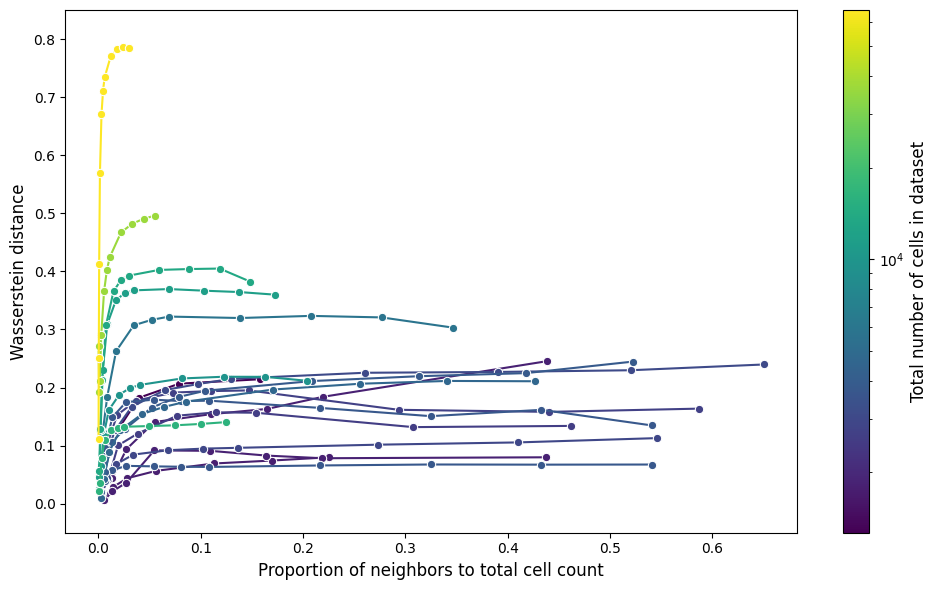

In [6]:
# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_df, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount', 
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legend
if ax.get_legend() is not None:
    ax.get_legend().remove()
sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Total number of cells in dataset', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.savefig("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes.pdf", transparent=True, dpi= 450)
plt.show()

### Subsampling of datasets
To check if the trend of "less cells lower Wasserstein distance" holds true, we subsamples the datasets and recomputed the embedding and then calculated the Wasserstein distance (see script: 0519_compute_k_subsets.py)

This first computation was not done for the sebra dataset as I included it later and we decided, that the computation with velocity recomputation is better

In [7]:
subsamples = {
        '/mnt/volume/Johanna_Velotest/results/neighbors/PBMC_cluster_fractions.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Human_HSC_cluster_fractions.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Hindbrain_mouse_cluster_fractions.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Oligodendrocyte_mouse_cluster_fractions.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Zebra_NMP_cluster_fractions_recomputed.csv'
    }

In [8]:
# Check the fractions for each cell dataset
for file in subsamples: 
    df = pd.read_csv(file, index_col=0)
    df.insert(0, 'variance', np.var(df, axis=1))
    display(df)

,variance,Zebra_NMP_original,Zebra_NMP_0.5,Zebra_NMP_0.25,Zebra_NMP_0.125
Cells_Annotations,,,,,
Endoderm,4.460795e-06,0.047272,0.047773,0.045160,0.042415
FloorPlate,1.154695e-08,0.012972,0.012972,0.012725,0.012974
Hindbrain,2.375479e-05,0.267228,0.258950,0.272455,0.264471
LateralPlate,1.374673e-07,0.018023,0.017712,0.018713,0.017964
Muscle,1.342458e-06,0.055379,0.055757,0.054142,0.057385
Myotome,1.759337e-06,0.019333,0.019583,0.016218,0.018463
NMPs,2.546204e-05,0.060306,0.061494,0.057385,0.070858
NeuralCrest,6.581464e-06,0.114125,0.117999,0.113772,0.110778
NeuralTube,3.454507e-06,0.095603,0.094175,0.095060,0.090818


,variance,Human_HSC_original,Human_HSC_0.5,Human_HSC_0.25,Human_HSC_0.125
leiden,,,,,
LMPP,3.805343e-05,0.145541,0.148225,0.152706,0.135862
HSC,9.909724e-06,0.142352,0.142882,0.148569,0.140000
MEP,4.397057e-06,0.142094,0.140641,0.144088,0.146207
MPP,2.665327e-05,0.136579,0.130817,0.132368,0.144138
Erythrocyte,1.013216e-06,0.111159,0.108928,0.109273,0.111034
GMP,7.288217e-06,0.105730,0.106343,0.104791,0.111724
Prog MK,4.452616e-06,0.104352,0.105653,0.102723,0.100000
Granulocyte,1.787091e-05,0.063852,0.065495,0.065150,0.055172
Prog DC,2.552450e-05,0.042740,0.044640,0.036194,0.050345


,variance,Hindbrain_mouse_original,Hindbrain_mouse_0.5,Hindbrain_mouse_0.25,Hindbrain_mouse_0.125
Celltype,,,,,
Neural stem cells,0.000024,0.291682,0.291556,0.295704,0.303497
Gliogenic progenitors,0.000008,0.199319,0.202667,0.206519,0.200356
GABA interneurons,0.000005,0.178802,0.176889,0.176889,0.172496
VZ progenitors,0.000005,0.145323,0.147407,0.147852,0.142264
Differentiating GABA interneurons,0.000015,0.104437,0.102963,0.096000,0.106106
Proliferating VZ progenitors,0.000004,0.080438,0.078519,0.077037,0.075282


,variance,Oligodendrocyte_mouse_original,Oligodendrocyte_mouse_0.5,Oligodendrocyte_mouse_0.25,Oligodendrocyte_mouse_0.125
Clusters,,,,,
19,2.935535e-07,0.022741,0.022464,0.023130,0.023904
21,4.364522e-06,0.043795,0.045040,0.046370,0.040726
22,2.655282e-08,0.000415,0.000332,0.000664,0.000221
26,8.300280e-06,0.173878,0.170531,0.178508,0.175520
32,1.169125e-07,0.001051,0.001328,0.001217,0.000443
34,0.000000e+00,0.000028,NaN,NaN,NaN
35,0.000000e+00,0.000055,NaN,NaN,NaN
36,8.424733e-09,0.000996,0.000996,0.001217,0.001107
37,1.424205e-05,0.242489,0.238311,0.247455,0.247233


,variance,PBMC_original,PBMC_0.5,PBMC_0.25,PBMC_0.125
celltype,,,,,
CD8+ Cytotoxic T,9.617261e-06,0.302700,0.302052,0.301293,0.309084
CD8+/CD45RA+ Naive Cytotoxic,4.106121e-06,0.243363,0.243245,0.244459,0.248239
CD56+ NK,9.075633e-07,0.128118,0.126693,0.125630,0.127641
CD4+/CD25 T Reg,4.342900e-06,0.089880,0.091019,0.091991,0.086471
CD19+ B,4.217009e-06,0.086130,0.088500,0.083187,0.084042
CD4+/CD45RO+ Memory,6.395659e-07,0.044705,0.044235,0.044933,0.042871
CD14+ Monocyte,7.705042e-07,0.041729,0.041320,0.042504,0.040078
Dendritic,1.995315e-06,0.030572,0.030330,0.033032,0.029147
CD4+/CD45RA+/CD25- Naive T,1.788504e-07,0.027354,0.026899,0.028053,0.027204


      index                Dataset  Measurement  CellCount  Neighbors  \
0      n_10                   PBMC     0.110775   65877.00         10   
1      n_25                   PBMC     0.250847   65877.00         25   
2      n_50                   PBMC     0.413394   65877.00         50   
3     n_100                   PBMC     0.569294   65877.00        100   
4     n_200                   PBMC     0.670491   65877.00        200   
..      ...                    ...          ...        ...        ...   
171   n_400  Oligodendrocyte_mouse     0.456346    4518.25        400   
172   n_800  Oligodendrocyte_mouse     0.477142    4518.25        800   
173  n_1200  Oligodendrocyte_mouse     0.467113    4518.25       1200   
174  n_1600  Oligodendrocyte_mouse     0.455086    4518.25       1600   
175  n_2000  Oligodendrocyte_mouse     0.434816    4518.25       2000   

     Proportion fraction  
0      0.000152      NaN  
1      0.000379      NaN  
2      0.000759      NaN  
3      0.001518

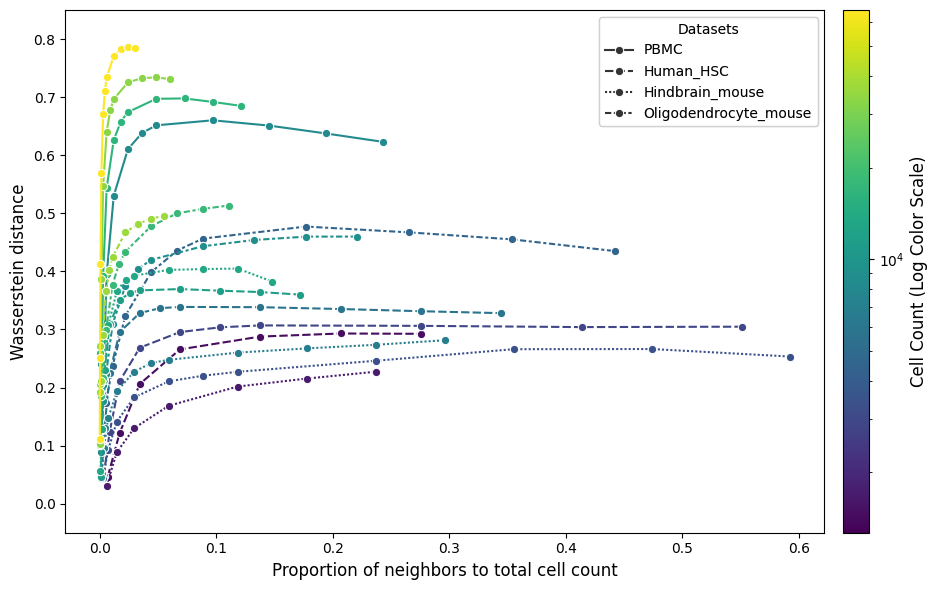

In [26]:
# Prepare dataset for plotting
df_sub_frac_embed = pd.read_csv("/mnt/volume/Johanna_Velotest/results/neighbors/k_sizes_test.csv", index_col=0)
df_complete_frac = df_complete[['PBMC', 'Human_HSC', 'Hindbrain_mouse', 'Oligodendrocyte_mouse']]

df_l_s = df_sub_frac_embed.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
df_l_s['fraction'] = df_l_s['Dataset'].str.split('_').str[-1]
df_l_s['Dataset'] = df_l_s['Dataset'].str.rsplit('_', n=1).str[0]

plot_s = pd.merge(df_l_s, count_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
plot_s['CellCount'] = plot_s['CellCount']*plot_s['fraction'].astype(float)
plot_s['Proportion'] = plot_s['Neighbors'] / plot_s['CellCount']

df_long = df_complete_frac.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')

plot_df = pd.merge(df_long, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']

plot_complete = pd.concat([plot_df, plot_s], ignore_index=True)
print(plot_complete)


# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount', 
    style='Dataset',    
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legends
handles, labels = ax.get_legend_handles_labels()
unique_datasets = plot_s['Dataset'].unique()
style_handles = []
style_labels = []

for h, l in zip(handles, labels):
    if l in unique_datasets:
        style_handles.append(h)
        style_labels.append(l)

if ax.get_legend() is not None:
    ax.get_legend().remove()
dataset_legend = ax.legend(
    style_handles, 
    style_labels, 
    title="Datasets", 
    loc='upper right',
    frameon=True
)
ax.add_artist(dataset_legend) # Prevents the colorbar from overwriting this legend

sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02) # Subtle pad to space it from the plot
cbar.set_label('Cell Count (Log Color Scale)', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.show()

### Redo the subsampling and recompute the embedding and the velocity

This is what we decided to do is more "right"

      index    Dataset  Measurement  CellCount  Neighbors  Proportion fraction
0      n_10       PBMC     0.110775  65877.000         10    0.000152      NaN
1      n_25       PBMC     0.250847  65877.000         25    0.000379      NaN
2      n_50       PBMC     0.413394  65877.000         50    0.000759      NaN
3     n_100       PBMC     0.569294  65877.000        100    0.001518      NaN
4     n_200       PBMC     0.670491  65877.000        200    0.003036      NaN
..      ...        ...          ...        ...        ...         ...      ...
215   n_400  Zebra_NMP     0.143015   2004.375        400    0.199563    0.125
216   n_800  Zebra_NMP     0.168742   2004.375        800    0.399127    0.125
217  n_1200  Zebra_NMP          NaN   2004.375       1200    0.598690    0.125
218  n_1600  Zebra_NMP          NaN   2004.375       1600    0.798254    0.125
219  n_2000  Zebra_NMP          NaN   2004.375       2000    0.997817    0.125

[220 rows x 7 columns]


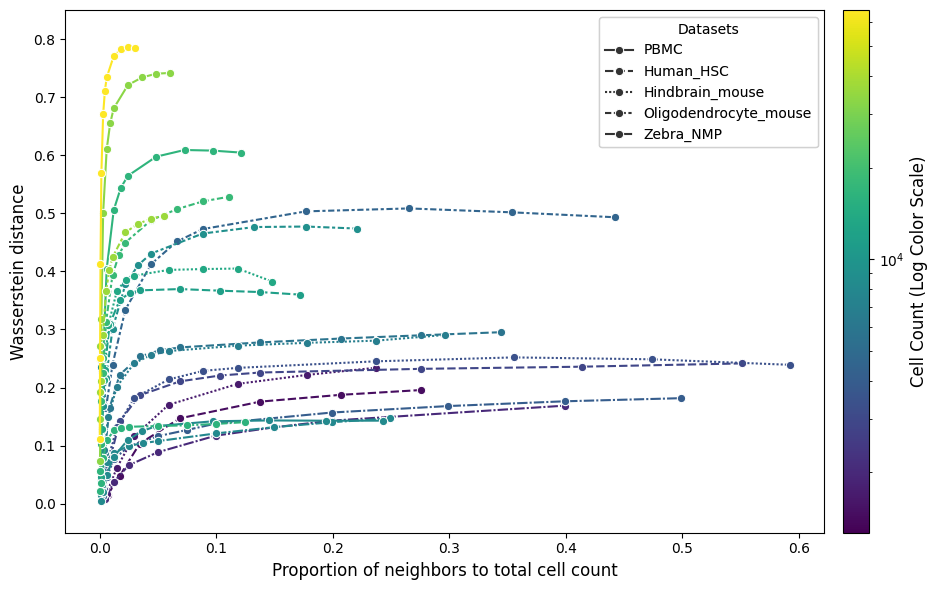

In [9]:
# Prepare dataset for plotting
df_sub_frac_embed_velo = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_fractions.csv", index_col=0)
df_complete_frac = df_complete[['PBMC', 'Human_HSC', 'Hindbrain_mouse', 'Oligodendrocyte_mouse', 'Zebra_NMP']]

df_l_s = df_sub_frac_embed_velo.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
df_l_s['fraction'] = df_l_s['Dataset'].str.split('_').str[-1]
df_l_s['Dataset'] = df_l_s['Dataset'].str.rsplit('_', n=1).str[0]

plot_s = pd.merge(df_l_s, count_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
plot_s['CellCount'] = plot_s['CellCount']*plot_s['fraction'].astype(float)
plot_s['Proportion'] = plot_s['Neighbors'] / plot_s['CellCount']

df_long = df_complete_frac.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')

plot_df = pd.merge(df_long, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']

plot_complete = pd.concat([plot_df, plot_s], ignore_index=True)
print(plot_complete)

# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount', 
    style='Dataset',    
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legends
handles, labels = ax.get_legend_handles_labels()
unique_datasets = plot_s['Dataset'].unique()
style_handles = []
style_labels = []

for h, l in zip(handles, labels):
    if l in unique_datasets:
        style_handles.append(h)
        style_labels.append(l)

if ax.get_legend() is not None:
    ax.get_legend().remove()
dataset_legend = ax.legend(
    style_handles, 
    style_labels, 
    title="Datasets", 
    loc='upper right',
    frameon=True
)
ax.add_artist(dataset_legend) # Prevents the colorbar from overwriting this legend

sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02) # Subtle pad to space it from the plot
cbar.set_label('Cell Count (Log Color Scale)', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.savefig("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_fractions.pdf", transparent=True, dpi= 450)
plt.show()

Alternative plotting idea, but still not convinced...

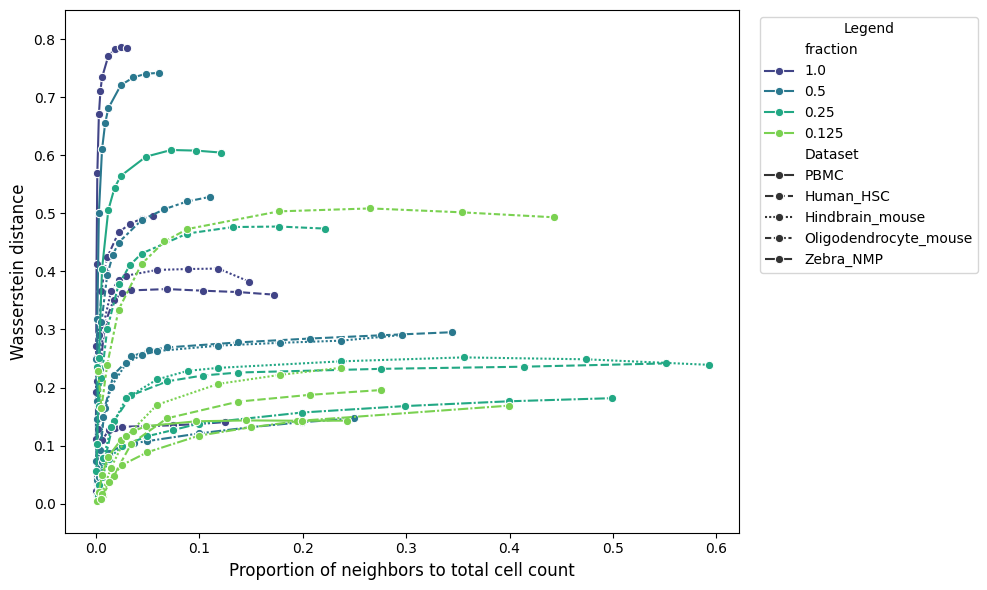

In [10]:
df_sub_frac_embed_velo = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_fractions.csv", index_col=0)
df_complete_frac = df_complete[['PBMC', 'Human_HSC', 'Hindbrain_mouse', 'Oligodendrocyte_mouse', 'Zebra_NMP']]

df_l_s = df_sub_frac_embed_velo.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
df_l_s['fraction'] = df_l_s['Dataset'].str.split('_').str[-1]
df_l_s['Dataset'] = df_l_s['Dataset'].str.rsplit('_', n=1).str[0]

plot_s = pd.merge(df_l_s, count_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
plot_s['CellCount'] = plot_s['CellCount'] * plot_s['fraction'].astype(float)
plot_s['Proportion'] = plot_s['Neighbors'] / plot_s['CellCount']

df_long = df_complete_frac.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')

plot_df = pd.merge(df_long, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']

# Add a fraction column to the complete datasets so it matches the subset dataframe
plot_df['fraction'] = '1.0' 

plot_complete = pd.concat([plot_df, plot_s], ignore_index=True)

# Ensure 'fraction' is treated as a discrete category (string) for coloring
plot_complete['fraction'] = plot_complete['fraction'].astype(str)

# Create a unique ID for each line so Seaborn doesn't connect points from different datasets 
plot_complete['Line_ID'] = plot_complete['Dataset'] + "_" + plot_complete['fraction']


# --- 2. Plot graph ---
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='fraction',       # Color by fraction instead of CellCount
    style='Dataset',    
    units='Line_ID',      # Use the unique Line_ID we created
    estimator=None,
    palette='viridis',    # Applies discrete colors from the viridis palette
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legends - Let Seaborn handle the combined legend, just move it outside the plot
ax.legend(
    title="Legend", 
    bbox_to_anchor=(1.02, 1), 
    loc='upper left',
    frameon=True
)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.savefig("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_fractions.pdf", transparent=True, dpi=450)
plt.show()

### Subsampling of datasets to a certain cell number
To check if the trend of "less cells lower Wasserstein distance" holds true, we subsamples the datasets and recomputed the embedding and then calculated the Wasserstein distance (see script: 0519_compute_k_subsets.py) --> adapted this script to subsmaple exactly 5000 cells


In [11]:
subsamples = {
        '/mnt/volume/Johanna_Velotest/results/neighbors/PBMC_cluster_cells_recomputed.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Human_HSC_cluster_cells_recomputed.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Hindbrain_mouse_cluster_cells_recomputed.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Oligodendrocyte_mouse_cluster_cells_recomputed.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Gastrulation_erythroid_cluster_cells_recomputed.csv',
        '/mnt/volume/Johanna_Velotest/results/neighbors/Zebra_NMP_cluster_5000cells_recomputed.csv'
    }

# Check the fractions for each cell dataset
for file in subsamples: 
    df = pd.read_csv(file, index_col=0)
    df.insert(0, 'variance', np.var(df, axis=1))
    display(df)

,variance,Zebra_NMP_original,Zebra_NMP_[5000]
Cells_Annotations,,,
Endoderm,4.411660e-07,0.047272,0.0486
FloorPlate,2.292764e-06,0.012972,0.0160
Hindbrain,1.454636e-05,0.267228,0.2596
LateralPlate,4.739809e-07,0.018023,0.0194
Muscle,8.376936e-08,0.055379,0.0548
Myotome,6.949642e-07,0.019333,0.0210
NMPs,1.814973e-06,0.060306,0.0630
NeuralCrest,2.646328e-08,0.114125,0.1138
NeuralTube,1.033960e-08,0.095603,0.0954


,variance,Hindbrain_mouse_original,Hindbrain_mouse_[5000]
Celltype,,,
Neural stem cells,1.163143e-07,0.291682,0.2910
Gliogenic progenitors,9.981079e-06,0.199319,0.1930
GABA interneurons,2.887331e-06,0.178802,0.1822
VZ progenitors,3.758618e-06,0.145323,0.1492
Differentiating GABA interneurons,6.666037e-09,0.104437,0.1046
Proliferating VZ progenitors,4.806750e-08,0.080438,0.0800


,variance,Human_HSC_original,Human_HSC_[5000]
leiden,,,
LMPP,1.680715e-08,0.145541,0.1458
HSC,1.628730e-06,0.142352,0.1398
MEP,6.487018e-06,0.142094,0.1370
MPP,4.041988e-06,0.136579,0.1406
Erythrocyte,8.529369e-06,0.111159,0.1170
GMP,3.478763e-06,0.105730,0.1020
Prog MK,1.753542e-06,0.104352,0.1070
Granulocyte,3.031290e-08,0.063852,0.0642
Prog DC,3.250130e-07,0.042740,0.0416


,variance,PBMC_original,PBMC_[5000]
celltype,,,
CD4+ T Helper2,3.931140e-08,0.001397,0.0010
CD4+/CD25 T Reg,2.073059e-06,0.089880,0.0870
CD4+/CD45RA+/CD25- Naive T,7.673128e-08,0.027354,0.0268
CD4+/CD45RO+ Memory,1.568161e-06,0.044705,0.0422
CD8+ Cytotoxic T,4.228168e-07,0.302700,0.3014
CD8+/CD45RA+ Naive Cytotoxic,6.612158e-09,0.243363,0.2432
CD14+ Monocyte,2.158919e-07,0.041729,0.0408
CD19+ B,9.210580e-06,0.086130,0.0922
CD34+,7.024588e-10,0.004053,0.0040


,variance,Gastrulation_erythroid_original,Gastrulation_erythroid_[5000]
celltype,,,
Erythroid1,8.470383e-06,0.298421,0.2926
Erythroid3,6.532724e-07,0.274783,0.2764
Blood progenitors 2,6.158387e-06,0.250637,0.2556
Erythroid2,5.097060e-06,0.112685,0.1172
Blood progenitors 1,6.954492e-06,0.063474,0.0582


,variance,Oligodendrocyte_mouse_original,Oligodendrocyte_mouse_[5000]
Clusters,,,
19,2.339209e-06,0.022741,0.0258
21,3.567737e-07,0.043795,0.0426
22,3.705939e-08,0.000415,0.0008
26,1.197796e-05,0.173878,0.1808
32,3.039932e-08,0.001051,0.0014
34,0.000000e+00,0.000028,NaN
35,0.000000e+00,0.000055,NaN
36,4.081191e-08,0.000996,0.0014
37,6.531103e-06,0.242489,0.2476


      index    Dataset  Measurement  CellCount  Neighbors  Proportion fraction
0      n_10       PBMC     0.110775    65877.0         10    0.000152      NaN
1      n_25       PBMC     0.250847    65877.0         25    0.000379      NaN
2      n_50       PBMC     0.413394    65877.0         50    0.000759      NaN
3     n_100       PBMC     0.569294    65877.0        100    0.001518      NaN
4     n_200       PBMC     0.670491    65877.0        200    0.003036      NaN
..      ...        ...          ...        ...        ...         ...      ...
127   n_400  Zebra_NMP     0.108487     5000.0        400    0.080000     5000
128   n_800  Zebra_NMP     0.124183     5000.0        800    0.160000     5000
129  n_1200  Zebra_NMP     0.136573     5000.0       1200    0.240000     5000
130  n_1600  Zebra_NMP     0.146862     5000.0       1600    0.320000     5000
131  n_2000  Zebra_NMP     0.154442     5000.0       2000    0.400000     5000

[132 rows x 7 columns]


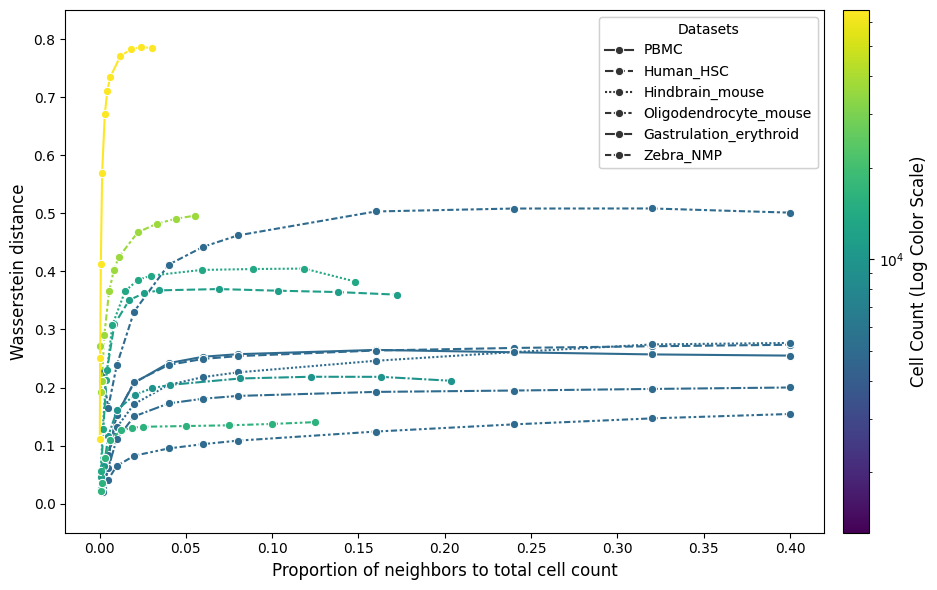

In [14]:
# Prepare dataset for plotting
df_sub_5000_all = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_sub_5000cells.csv", index_col=0)
df_complete_5000 = df_complete[['PBMC', 'Human_HSC', 'Hindbrain_mouse', 'Oligodendrocyte_mouse', 'Gastrulation_erythroid', 'Zebra_NMP']]

df_l_s = df_sub_5000_all.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
df_l_s['fraction'] = "5000"
df_l_s['Dataset'] = df_l_s['Dataset'].str.rsplit('_', n=1).str[0]

plot_s = pd.merge(df_l_s, count_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
plot_s['CellCount'] = plot_s['fraction'].astype(float)
plot_s['Proportion'] = plot_s['Neighbors'] / plot_s['CellCount']

df_long = df_complete_5000.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')

plot_df = pd.merge(df_long, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']

plot_complete = pd.concat([plot_df, plot_s], ignore_index=True)
print(plot_complete)

# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount', 
    style='Dataset',    
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legends
handles, labels = ax.get_legend_handles_labels()
unique_datasets = plot_s['Dataset'].unique()
style_handles = []
style_labels = []

for h, l in zip(handles, labels):
    if l in unique_datasets:
        style_handles.append(h)
        style_labels.append(l)

if ax.get_legend() is not None:
    ax.get_legend().remove()
dataset_legend = ax.legend(
    style_handles, 
    style_labels, 
    title="Datasets", 
    loc='upper right',
    frameon=True
)
ax.add_artist(dataset_legend) # Prevents the colorbar from overwriting this legend

sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02) # Subtle pad to space it from the plot
cbar.set_label('Cell Count (Log Color Scale)', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.savefig("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_5000cells.pdf", transparent=True, dpi= 450)
plt.show()

### Subsampling down to 2.000 cells where it is possible

Plot those cells results as well

In [15]:
# Load new dataset for 2000 subsampled cells
df_sub_2000_all = pd.read_csv("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_sub_2000cells.csv", index_col=0)
df_l_sub_2000_all = df_sub_2000_all.reset_index().melt(var_name='Dataset', value_name='Measurement', id_vars='index')
df_l_sub_2000_all['Dataset'] = df_l_sub_2000_all['Dataset'].str.rsplit('_', n=1).str[0]

     index             Dataset  Measurement  CellCount  Neighbors  Proportion
0     n_10  Pancreas_dynamical     0.032677       3696         10      0.0050
1     n_25  Pancreas_dynamical     0.074961       3696         25      0.0125
2     n_50  Pancreas_dynamical     0.108980       3696         50      0.0250
3    n_100  Pancreas_dynamical     0.130683       3696        100      0.0500
4    n_200  Pancreas_dynamical     0.137695       3696        200      0.1000
..     ...                 ...          ...        ...        ...         ...
115  n_100           Zebra_NMP     0.091628      16035        100      0.0500
116  n_200           Zebra_NMP     0.121161      16035        200      0.1000
117  n_300           Zebra_NMP     0.135652      16035        300      0.1500
118  n_400           Zebra_NMP     0.147717      16035        400      0.2000
119  n_800           Zebra_NMP     0.171153      16035        800      0.4000

[120 rows x 6 columns]


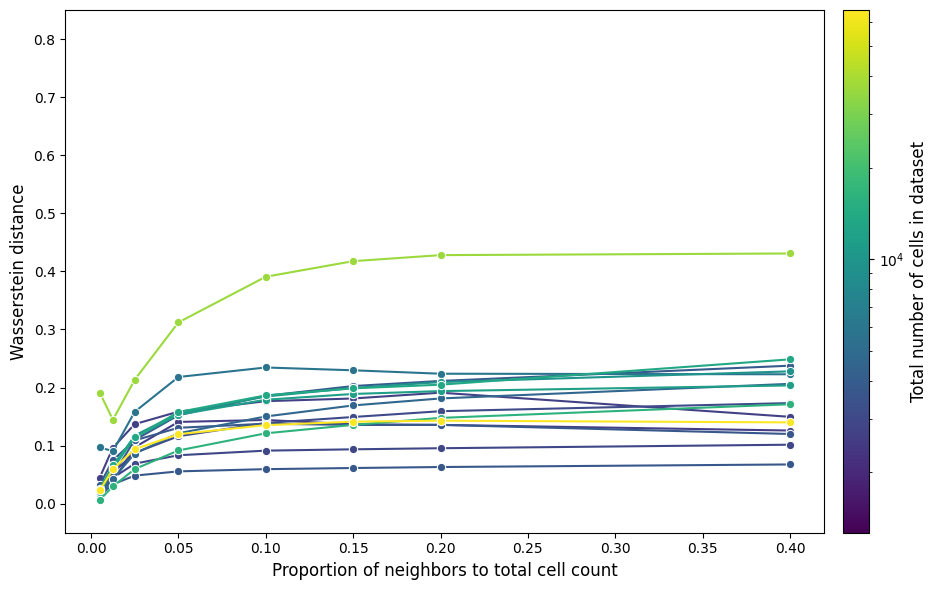

In [16]:
# Prepare dataset further for cell counts
plot_s = pd.merge(df_l_sub_2000_all, count_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
#plot_s['CellCount'] = plot_s['fraction'].astype(float)
plot_s['Proportion'] = plot_s['Neighbors'] / 2000

plot_complete = plot_s.copy()
print(plot_complete)

# Plot graph
plt.figure(figsize=(10, 6))


ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='CellCount',    
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm,
    marker='o',       
    linewidth=1.5,
    markersize=6
)
ax.legend_.remove() # Remove legend to only have the colorbar
sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02) # Subtle pad to space it from the plot
cbar.set_label('Total number of cells in dataset', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.savefig("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_2000cells.pdf", transparent=True, dpi= 450)
plt.show()

### Replot graphs based on dimensions
After we considered, that the dimension of velocity genes might have a higher influence than cell number I plottd the two main graphs again, building the color scale based on the velocity genes (dimensions) 

      index             Dataset  Measurement  VelocityGenes  CellCount  \
0      n_10  Pancreas_dynamical     0.041831           1027       3696   
1      n_25  Pancreas_dynamical     0.095621           1027       3696   
2      n_50  Pancreas_dynamical     0.148577           1027       3696   
3     n_100  Pancreas_dynamical     0.174910           1027       3696   
4     n_200  Pancreas_dynamical     0.179060           1027       3696   
..      ...                 ...          ...            ...        ...   
204   n_400           Zebra_NMP     0.132425            897      16035   
205   n_800           Zebra_NMP     0.133671            897      16035   
206  n_1200           Zebra_NMP     0.134934            897      16035   
207  n_1600           Zebra_NMP     0.137269            897      16035   
208  n_2000           Zebra_NMP     0.140408            897      16035   

     Neighbors  Proportion  
0           10    0.002706  
1           25    0.006764  
2           50    0.0135

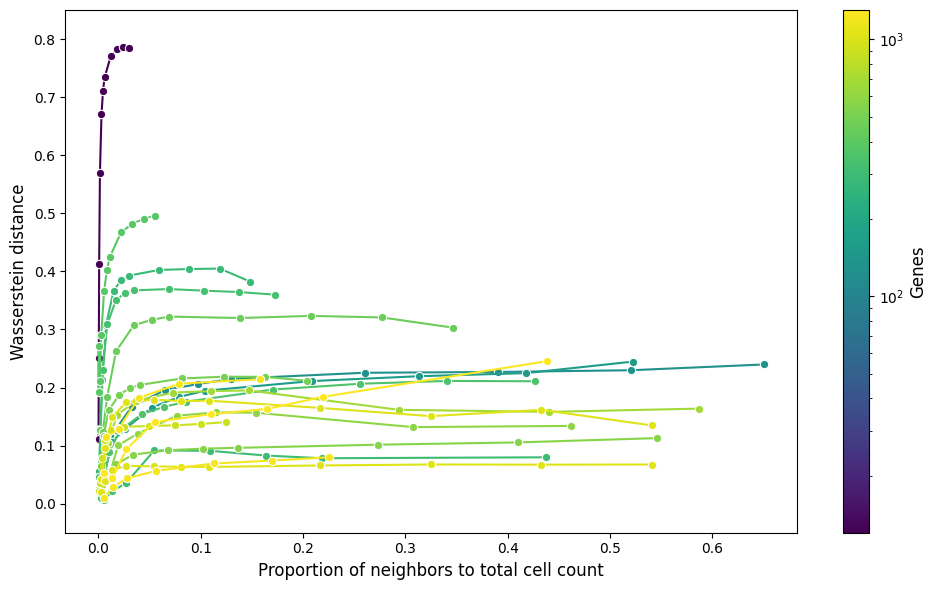

In [17]:
# Prepare datasets so that gene counts are included
plot_s = pd.merge(df_long_complete, gene_df, on='Dataset')

plot_df = pd.merge(plot_s, count_df, on='Dataset')
plot_df['Neighbors'] = plot_df['index'].str.replace('n_', '').astype(int)
plot_df['Proportion'] = plot_df['Neighbors'] / plot_df['CellCount']
print(plot_df)

# Prepare color scale 
vmin_genes = plot_df['VelocityGenes'].min()
vmax_genes = plot_df['VelocityGenes'].max()
log_norm_genes = LogNorm(vmin=vmin_genes, vmax=vmax_genes)

# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_df, 
    x='Proportion', 
    y='Measurement', 
    hue='VelocityGenes', 
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm_genes,
    marker='o',       
    linewidth=1.5,
    markersize=6
)

# Legend
if ax.get_legend() is not None:
    ax.get_legend().remove()
sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm_genes)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Genes', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.savefig("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_colored_genes.pdf", transparent=True, dpi= 450)
plt.show()

     index             Dataset  Measurement  VelocityGenes  Neighbors  \
0     n_10  Pancreas_dynamical     0.032677           1027         10   
1     n_25  Pancreas_dynamical     0.074961           1027         25   
2     n_50  Pancreas_dynamical     0.108980           1027         50   
3    n_100  Pancreas_dynamical     0.130683           1027        100   
4    n_200  Pancreas_dynamical     0.137695           1027        200   
..     ...                 ...          ...            ...        ...   
115  n_100           Zebra_NMP     0.091628            897        100   
116  n_200           Zebra_NMP     0.121161            897        200   
117  n_300           Zebra_NMP     0.135652            897        300   
118  n_400           Zebra_NMP     0.147717            897        400   
119  n_800           Zebra_NMP     0.171153            897        800   

     Proportion  
0        0.0050  
1        0.0125  
2        0.0250  
3        0.0500  
4        0.1000  
..          ...

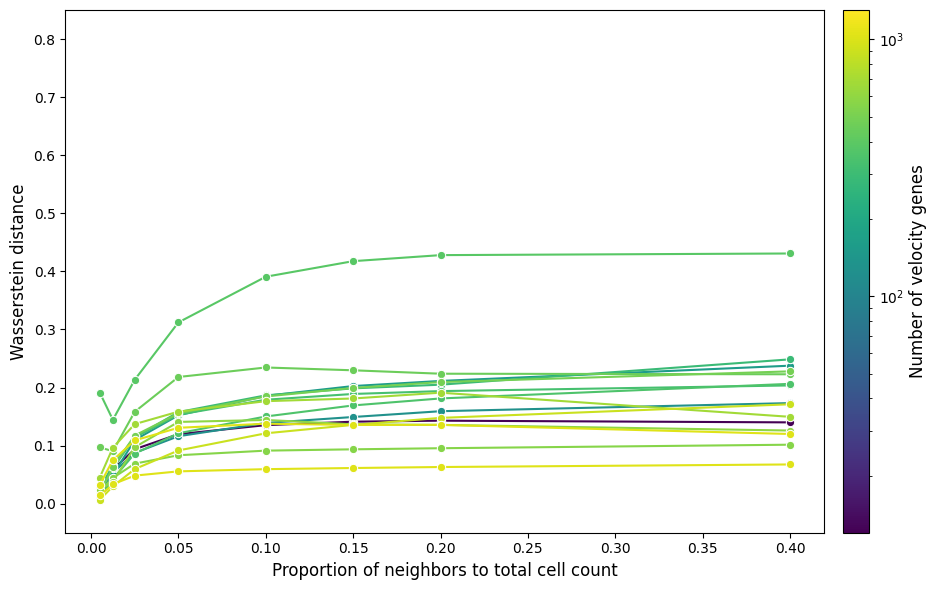

In [18]:
# Prepare dataset for ploting with genes
plot_s = pd.merge(df_l_sub_2000_all, gene_df, on='Dataset')
plot_s['Neighbors'] = plot_s['index'].str.replace('n_', '').astype(int)
plot_s['Proportion'] = plot_s['Neighbors'] / 2000

plot_complete = plot_s.copy()
print(plot_complete)

# Plot graph
plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=plot_complete, 
    x='Proportion', 
    y='Measurement', 
    hue='VelocityGenes',    
    units='Dataset',
    estimator=None,
    palette='viridis', 
    hue_norm=log_norm_genes,
    marker='o',       
    linewidth=1.5,
    markersize=6
)
ax.legend_.remove() # Remove legend to only have the colorbar
sm = plt.cm.ScalarMappable(cmap="viridis", norm=log_norm_genes)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.02) # Subtle pad to space it from the plot
cbar.set_label('Number of velocity genes', fontsize=12)

plt.ylabel('Wasserstein distance', fontsize=12)
plt.xlabel('Proportion of neighbors to total cell count', fontsize=12) 
plt.ylim(-0.05, 0.85)

plt.tight_layout()
plt.savefig("/mnt/volume/Johanna_Velotest/results/final_distance_tables/influence_k_sizes_2000cells_colored_genes.pdf", transparent=True, dpi= 450)
plt.show()